# Mini Project 13 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_13.py` (bagian wajib) dan `features/mp13_extension_evaluation_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 13 — Membuka Test Set Sekali dan Membekukan Laporan Evaluasi
Model klasik MP11 dan Tiny CNN MP12 dievaluasi pada test set beku MP9 **tanpa mengubah model**.
SHA-256 artefak dihitung sebelum & sesudah test (audit trail). Kedua kandidat diteruskan;
keputusan deployment ditunda ke MP15. Status -> `ready_for_mp14`.

Catatan lokasi: buku menaruh skrip di `scripts/mini_project_13.py`; pada running project ini
seluruh skrip mini project konsisten berada di root folder mini project (ROOT dihitung otomatis).

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json, csv, hashlib, math
import numpy as np
import joblib
import torch
import torch.nn as nn
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    balanced_accuracy_score, confusion_matrix
)

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
TARGET_FRAMES = 96
ALPHA_Z = 1.96  # 95% Wilson interval

## Helper: SHA-256, Wilson interval, metrik lengkap

In [2]:
def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2), encoding='utf-8')


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def wilson_interval(k, n, z=1.96):
    if n == 0:
        return [0.0, 1.0]
    p = k / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z * math.sqrt((p*(1-p)/n) + (z*z/(4*n*n))) / den
    return [max(0.0, center-half), min(1.0, center+half)]


def model_metrics(y_true, y_pred, labels):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    acc = float(accuracy_score(y_true, y_pred))
    out = {
        'accuracy': acc,
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'macro_precision': float(np.mean(p)),
        'macro_recall': float(np.mean(r)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'accuracy_wilson_95': wilson_interval(int(np.sum(np.asarray(y_true) == np.asarray(y_pred))), len(y_true), ALPHA_Z),
        'per_class': {},
        'confusion_matrix': confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }
    for i, c in enumerate(labels):
        out['per_class'][c] = {'precision': float(p[i]), 'recall': float(r[i]), 'f1': float(f[i]), 'support': int(s[i])}
    return out

## 0) Gate serial dan pre-test audit (hash dibekukan SEBELUM test dibuka)

In [3]:
status_path = ROOT / 'project_status.json'
status = json.loads(status_path.read_text(encoding='utf-8'))
REPRODUCTION_RUN = status.get('status') == 'ready_for_mp14'   # eksekusi ulang = reproduksi, bukan tuning
if status.get('status') not in ('ready_for_mp13', 'ready_for_mp14'):
    raise RuntimeError(f"Status harus ready_for_mp13, ditemukan {status.get('status')!r}")

clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
dl_cfg = json.loads((ROOT/'config/deep_learning_config.json').read_text(encoding='utf-8'))
if clf_cfg.get('test_predictions_generated') or dl_cfg.get('test_predictions_generated'):
    raise RuntimeError('Gate gagal: salah satu model sudah pernah membuat test prediction sebelum MP13.')

split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
test_ids = list(split['test_ids'])
classes = list(clf_cfg['classes'])
if classes != list(dl_cfg['classes']):
    raise RuntimeError('Urutan kelas MP11 dan MP12 tidak identik.')

freeze_files = [
    ROOT/'models/mp11_classical_baseline.joblib',
    ROOT/'models/mp11_model_parameters.npz',
    ROOT/'config/classifier_config.json',
    ROOT/'models/mp12_tiny_cnn_state.pt',
    ROOT/'models/mp12_tiny_cnn_parameters.npz',
    ROOT/'config/deep_learning_config.json',
    ROOT/'config/feature_reduction_config.json',
    ROOT/'config/feature_config.json',
    ROOT/'splits/mp09_split.json',
]
for p in freeze_files:
    if not p.exists():
        raise FileNotFoundError(p)
pretest_hashes = {p.relative_to(ROOT).as_posix(): sha256(p) for p in freeze_files}
if REPRODUCTION_RUN:
    old = json.loads((ROOT/'results/metrics/mp13_pretest_artifact_hashes.json').read_text(encoding='utf-8'))
    if old != pretest_hashes:
        raise RuntimeError('Reproduksi ditolak: artefak berubah sejak test pertama kali dibuka.')

protocol = {
    'name': 'MP13 final frozen-test comparison',
    'test_open_policy': 'open_once_after_all_models_are_frozen',
    'test_ids': test_ids,
    'n_test': len(test_ids),
    'primary_metric': 'macro_f1',
    'secondary_metrics': ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall'],
    'confidence_interval': 'Wilson 95% interval for accuracy',
    'post_test_tuning_allowed': False,
    'deployment_model_selection_from_test_allowed': False,
    'deployment_candidates_forwarded': ['mp11_classical_baseline', 'mp12_tiny_cnn'],
    'device_based_selection_deferred_to': 'MP15',
    'warning': 'Test set is very small; metrics are demonstrative and statistically uncertain.'
}
save_json(ROOT/'config/evaluation_protocol.json', protocol)
save_json(ROOT/'results/metrics/mp13_pretest_artifact_hashes.json', pretest_hashes)
print('PRE-TEST GATE VALID | test ids =', test_ids, '| reproduction run =', REPRODUCTION_RUN)

PRE-TEST GATE VALID | test ids = ['ezra_nyala_b06', 'ezra_mati_b06', 'ezra_naik_b06', 'ezra_turun_b06', 'abdillah_nyala_b06', 'abdillah_mati_b06', 'abdillah_naik_b06', 'abdillah_turun_b06', 'ivang_nyala_b06', 'ivang_mati_b06', 'ivang_naik_b06', 'ivang_turun_b06', 'jahzeel_nyala_b06', 'jahzeel_mati_b06', 'jahzeel_naik_b06', 'jahzeel_turun_b06'] | reproduction run = True


## 1) Buka test set untuk baseline klasik

In [4]:
D = np.load(ROOT/'features/dataset/mp10_features_final.npz', allow_pickle=True)
X = D['X'].astype(np.float64)
y = D['y'].astype(str)
sample_ids = D['sample_ids'].astype(str)
test_mask = D['test_mask'].astype(bool)
idx_by_id = {sid: i for i, sid in enumerate(sample_ids)}
idx = np.array([idx_by_id[sid] for sid in test_ids], dtype=int)
if not np.all(test_mask[idx]):
    raise RuntimeError('Test ID tidak cocok dengan test_mask yang dibekukan.')
X_test = X[idx]
y_test = y[idx]

classical = joblib.load(ROOT/'models/mp11_classical_baseline.joblib')
pred_classical = classical.predict(X_test).astype(str)
# Margin hanya confidence proxy, bukan calibrated probability.
if hasattr(classical, 'decision_function'):
    scores = np.asarray(classical.decision_function(X_test))
    if scores.ndim == 1:
        margin_classical = np.abs(scores)
    else:
        ss = np.sort(scores, axis=1)
        margin_classical = ss[:, -1] - ss[:, -2]
else:
    margin_classical = np.full(len(y_test), np.nan)

## 2) Buka log-Mel test untuk CNN

In [5]:
class TinyKWSNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(16, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


ckpt = torch.load(ROOT/'models/mp12_tiny_cnn_state.pt', map_location='cpu', weights_only=False)
if list(ckpt['classes']) != classes:
    raise RuntimeError('Kelas checkpoint CNN tidak cocok.')
mu = float(ckpt['normalization']['mean']); sigma = float(ckpt['normalization']['std'])
model = TinyKWSNet(len(classes)); model.load_state_dict(ckpt['state_dict']); model.eval()

logmels = []
labels_dl = []
for sid in test_ids:
    p = ROOT/'features/logmel/mp09'/f'{sid}.npz'
    d = np.load(p, allow_pickle=True)
    x = d['log_mel'].astype(np.float32)
    if x.shape[0] >= TARGET_FRAMES:
        x = x[:TARGET_FRAMES]
    else:
        fill = float(np.min(x)) if x.size else 0.0
        x = np.pad(x, ((0, TARGET_FRAMES-x.shape[0]), (0, 0)), mode='constant', constant_values=fill)
    logmels.append((x-mu)/sigma)
    labels_dl.append(str(d['label']))
if labels_dl != y_test.tolist():
    raise RuntimeError('Label test log-Mel dan dataset klasik tidak identik pada urutan test_ids.')
Xdl = torch.from_numpy(np.stack(logmels)[:, None, :, :]).float()
with torch.no_grad():
    logits = model(Xdl)
    prob = torch.softmax(logits, dim=1).cpu().numpy()
    pred_idx = prob.argmax(axis=1)
pred_cnn = np.asarray([classes[i] for i in pred_idx], dtype=str)
conf_cnn = prob.max(axis=1)

## 3) Metrik final, TANPA mengubah model

In [6]:
metrics_classical = model_metrics(y_test, pred_classical, classes)
metrics_cnn = model_metrics(y_test, pred_cnn, classes)
mp11_metrics = json.loads((ROOT/'results/metrics/mp11_classifier_metrics.json').read_text(encoding='utf-8'))
mp12_metrics = json.loads((ROOT/'results/metrics/mp12_deep_learning_metrics.json').read_text(encoding='utf-8'))
resource = {
    'classical': {
        'family': clf_cfg['chosen_family'],
        **mp11_metrics['family_results'][clf_cfg['chosen_family']]['resource_proxy'],
        'note': 'Classifier-only resource proxy; feature extraction cost is not included.'
    },
    'tiny_cnn': {
        'parameter_count': mp12_metrics['parameter_count'],
        'float32_parameter_bytes': mp12_metrics['float32_parameter_bytes'],
        'estimated_int8_parameter_bytes': mp12_metrics['estimated_int8_parameter_bytes'],
        'estimated_macs_per_inference': mp12_metrics['estimated_macs_per_inference'],
        'note': 'Architecture proxy; measured latency/RAM/energy are deferred to MP15.'
    }
}
report = {
    'test_opened': True,
    'test_opened_once_in_running_project': True,
    'reproduction_run': REPRODUCTION_RUN,
    'n_test': int(len(y_test)),
    'classes': classes,
    'sample_ids': test_ids,
    'classical': metrics_classical,
    'tiny_cnn': metrics_cnn,
    'resource_proxy': resource,
    'post_test_tuning_performed': False,
    'deployment_selection_from_test_performed': False,
    'deployment_candidates_forwarded': ['mp11_classical_baseline', 'mp12_tiny_cnn'],
    'interpretation_warning': f'With only {len(test_ids)} test samples (known speakers, new session), point estimates have wide uncertainty; '
                              'see the Wilson intervals. Do not claim generalization to unseen speakers.',
}
if REPRODUCTION_RUN:
    prev = json.loads((ROOT/'results/metrics/mp13_final_test_metrics.json').read_text(encoding='utf-8'))
    assert prev['classical'] == metrics_classical and prev['tiny_cnn'] == metrics_cnn, 'Reproduksi tidak identik!'
save_json(ROOT/'results/metrics/mp13_final_test_metrics.json', report)

# Per-sample audit trail.
pred_dir = ROOT/'results/predictions'; pred_dir.mkdir(parents=True, exist_ok=True)
with open(pred_dir/'mp13_test_predictions.csv', 'w', newline='', encoding='utf-8') as f:
    w = csv.writer(f)
    w.writerow(['sample_id', 'true_label', 'classical_prediction', 'classical_margin_proxy', 'cnn_prediction', 'cnn_max_softmax'])
    for i, sid in enumerate(test_ids):
        w.writerow([sid, y_test[i], pred_classical[i], float(margin_classical[i]), pred_cnn[i], float(conf_cnn[i])])
print(open(pred_dir/'mp13_test_predictions.csv', encoding='utf-8').read())

sample_id,true_label,classical_prediction,classical_margin_proxy,cnn_prediction,cnn_max_softmax
ezra_nyala_b06,nyala,nyala,2.629501644820838,mati,0.341493159532547
ezra_mati_b06,mati,mati,2.7529923778042096,mati,0.3999077379703522
ezra_naik_b06,naik,naik,3.149585414631563,naik,0.2791000008583069
ezra_turun_b06,turun,naik,1.0133002071987411,mati,0.26843953132629395
abdillah_nyala_b06,nyala,nyala,0.8181065753520269,naik,0.28290197253227234
abdillah_mati_b06,mati,mati,0.15773673083373946,turun,0.3166853189468384
abdillah_naik_b06,naik,naik,3.8368087652215146,naik,0.28282666206359863
abdillah_turun_b06,turun,turun,3.1649731052642673,turun,0.31090041995048523
ivang_nyala_b06,nyala,nyala,4.58730291574697,nyala,0.32644253969192505
ivang_mati_b06,mati,mati,1.9479216471050065,turun,0.292843759059906
ivang_naik_b06,naik,naik,2.2382269052508357,nyala,0.303833544254303
ivang_turun_b06,turun,turun,0.6977542045728451,turun,0.33893436193466187
jahzeel_nyala_b06,nyala,nyala,4.628203200903822,nyala,0.3

## 4) Gambar evaluasi

In [7]:
fig_dir = ROOT/'results/figures'; fig_dir.mkdir(parents=True, exist_ok=True)
cm1 = np.asarray(metrics_classical['confusion_matrix']); cm2 = np.asarray(metrics_cnn['confusion_matrix'])
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, cm, title in zip(axes, [cm1, cm2], [f"MP11 classical ({clf_cfg['chosen_family']})", 'MP12 Tiny CNN']):
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=max(1, cm.max()))
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=35, ha='right'); ax.set_yticklabels(classes)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual'); ax.set_title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center')
fig.tight_layout(); fig.savefig(fig_dir/'mp13_test_confusion_matrices.png', dpi=180); plt.close(fig)

names = ['Accuracy', 'Balanced Acc.', 'Macro Precision', 'Macro Recall', 'Macro F1']
keys = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
x = np.arange(len(names)); width = .36
fig, ax = plt.subplots(figsize=(8.4, 4.1))
ax.bar(x-width/2, [metrics_classical[k] for k in keys], width, label='Classical')
ax.bar(x+width/2, [metrics_cnn[k] for k in keys], width, label='Tiny CNN')
ax.set_ylim(0, 1.08); ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha='right'); ax.set_ylabel('Skor'); ax.legend(); ax.grid(axis='y', alpha=.2)
fig.tight_layout(); fig.savefig(fig_dir/'mp13_test_metric_comparison.png', dpi=180); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.6, 4.0))
labels = ['Classical\nops proxy', 'Tiny CNN\nMAC proxy']
vals = [max(1, resource['classical']['estimated_ops_per_sample']), resource['tiny_cnn']['estimated_macs_per_inference']]
ax.bar(labels, vals); ax.set_yscale('log'); ax.set_ylabel('Operasi per inference (log scale)'); ax.grid(axis='y', alpha=.2)
for i, v in enumerate(vals): ax.text(i, v*1.15, f'{v:,}', ha='center')
fig.tight_layout(); fig.savefig(fig_dir/'mp13_resource_proxy.png', dpi=180); plt.close(fig)

## 5) Hash sesudah test: model/config tidak boleh berubah

In [8]:
posttest_hashes = {p.relative_to(ROOT).as_posix(): sha256(p) for p in freeze_files}
if posttest_hashes != pretest_hashes:
    raise RuntimeError('Artefak model/config berubah selama evaluasi test.')
save_json(ROOT/'results/metrics/mp13_posttest_artifact_hashes.json', posttest_hashes)
print('HASH VALID: model/config tidak berubah selama final test')

HASH VALID: model/config tidak berubah selama final test


## 6) Update status serial: kedua kandidat dibawa ke MP14/MP15

In [9]:
status['status'] = 'ready_for_mp14'
status['last_completed_mini_project'] = 13
status['mp13'] = {
    'evaluation_protocol': 'config/evaluation_protocol.json',
    'final_test_metrics': 'results/metrics/mp13_final_test_metrics.json',
    'test_predictions': 'results/predictions/mp13_test_predictions.csv',
    'pretest_hashes': 'results/metrics/mp13_pretest_artifact_hashes.json',
    'posttest_hashes': 'results/metrics/mp13_posttest_artifact_hashes.json',
    'test_opened': True,
    'post_test_tuning_performed': False,
    'deployment_candidates': ['models/mp11_classical_baseline.joblib', 'models/mp12_tiny_cnn_state.pt'],
    'deployment_selection_deferred_to': 'MP15'
}
save_json(status_path, status)

print('MP13 VALID: final frozen test evaluated once')
print('classical macro-F1 =', round(metrics_classical['macro_f1'], 4))
print('tiny CNN macro-F1 =', round(metrics_cnn['macro_f1'], 4))
print('classical accuracy 95% Wilson =', [round(v, 4) for v in metrics_classical['accuracy_wilson_95']])
print('tiny CNN accuracy 95% Wilson =', [round(v, 4) for v in metrics_cnn['accuracy_wilson_95']])
print('post-test tuning = False')
print('status = ready_for_mp14')

MP13 VALID: final frozen test evaluated once
classical macro-F1 = 0.9365
tiny CNN macro-F1 = 0.5595
classical accuracy 95% Wilson = [0.7167, 0.9889]
tiny CNN accuracy 95% Wilson = [0.3318, 0.769]
post-test tuning = False
status = ready_for_mp14


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp13_extension_evaluation_analysis.py`

## FITUR TAMBAHAN MP13 — Uncertainty, Uji Signifikansi, Kalibrasi, ROC/PR & Robustness Stress Test
Modul mandiri setelah `mini_project_13.py`. **Tidak ada post-test tuning**: semua model dibaca
beku (hash diverifikasi), hasil di sini tidak dipakai untuk memilih/mengubah model.

Fitur tambahan (materi Bab 13: uncertainty, ROC/PR, calibration/Brier, distribusi kesalahan):
1. **Bootstrap 95% CI** macro-F1 & accuracy (sampel test di-resample).
2. **Uji McNemar exact** classical vs CNN (apakah perbedaan signifikan?).
3. **Kalibrasi**: Brier score, NLL, ECE + reliability diagram (CNN softmax & probabilitas model klasik terpilih).
4. **ROC-AUC & PR-AP one-vs-rest** per kelas.
5. **Robustness stress test** pada WAV test: derau putih SNR 30→0 dB, gain −12/+6 dB, time-shift,
   memakai front-end beku `kws_frontend.py` (MP9) → kurva degradasi per model.
6. **Evaluasi eksploratif** semua kandidat beku MP11 (arsip keluarga) & varian CNN MP12
   (registry SHA-256) — dilaporkan terpisah, BUKAN dasar seleksi deployment.

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [10]:
from pathlib import Path
import json, hashlib, sys, warnings, importlib.util
from math import comb
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, average_precision_score

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT/'features'))
from kws_frontend import KWSFrontend  # noqa: E402

status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp14',), 'Jalankan mini_project_13.py terlebih dahulu'
rep = json.loads((ROOT/'results/metrics/mp13_final_test_metrics.json').read_text(encoding='utf-8'))
clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
dl_cfg = json.loads((ROOT/'config/deep_learning_config.json').read_text(encoding='utf-8'))
red = json.loads((ROOT/'config/feature_reduction_config.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
classes = rep['classes']; c2i = {c: i for i, c in enumerate(classes)}
test_ids = split['test_ids']
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'
fe = KWSFrontend(ROOT)
SEL = np.asarray(red['selected_indices'], int)
MU39 = np.asarray(red['scaler_mean']); SC39 = np.asarray(red['scaler_scale'])
rng = np.random.default_rng(2026)


def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


# Arsitektur CNN (resmi + varian eksplorasi) dimuat dari skrip MP12 tambahan agar identik
spec = importlib.util.spec_from_file_location('mp12x', ROOT/'features/mp12_extension_cnn_analysis.py')
src12 = (ROOT/'features/mp12_extension_cnn_analysis.py').read_text(encoding='utf-8')
arch_ns = {'nn': nn, 'torch': torch, 'np': np, 'random': __import__('random'), 'F': 26, 'classes': classes}
for cls_name in ('TinyKWSNet', 'DSCNN', 'TinyKWSFreqPool'):
    s0 = src12.index(f'class {cls_name}(')
    s1 = src12.index('\n\n\n', s0)
    exec(src12[s0:s1], arch_ns)

### Muat semua model beku + verifikasi hash

In [11]:
models = {}
official_hash = json.loads((ROOT/'results/metrics/mp13_pretest_artifact_hashes.json').read_text(encoding='utf-8'))
assert sha(ROOT/'models/mp11_classical_baseline.joblib') == official_hash['models/mp11_classical_baseline.joblib']
assert sha(ROOT/'models/mp12_tiny_cnn_state.pt') == official_hash['models/mp12_tiny_cnn_state.pt']
models['classical_' + clf_cfg['chosen_family'] + ' (resmi)'] = ('sk', joblib.load(ROOT/clf_cfg['model_file']))


def load_cnn(path, arch):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    net = arch_ns[arch](len(classes)); net.load_state_dict(ck['state_dict']); net.eval()
    return ('cnn', net, float(ck['normalization']['mean']), float(ck['normalization']['std']))


models['tiny_cnn (resmi)'] = load_cnn(ROOT/dl_cfg['model_file'], 'TinyKWSNet')
hash_ok = {}
mp11x = ROOT/'results/metrics/mp11_extension_classifier_metrics.json'
if mp11x.exists():
    for fam, info in json.loads(mp11x.read_text(encoding='utf-8'))['frozen_family_archive'].items():
        ok = sha(ROOT/info['file']) == info['sha256']; hash_ok[f'mp11_{fam}'] = ok
        if ok and fam != clf_cfg['chosen_family']:
            models[f'mp11_{fam} (eksplorasi)'] = ('sk', joblib.load(ROOT/info['file']))
reg = ROOT/'config/mp12_extension_candidates.json'
if reg.exists():
    for name, info in json.loads(reg.read_text(encoding='utf-8')).items():
        ok = sha(ROOT/info['file']) == info['sha256']; hash_ok[f'mp12_{name}'] = ok
        if ok:
            models[f'cnn_{name} (eksplorasi)'] = load_cnn(ROOT/info['file'], info['architecture'])
print('Hash eksplorasi valid:', hash_ok)
print('Model dievaluasi:', list(models))


def predict(m, v39_list, lm_list):
    """Return (pred labels, prob matrix or None)."""
    if m[0] == 'sk':
        Z = ((np.stack(v39_list)-MU39)/SC39)[:, SEL]
        pr = m[1].predict(Z).astype(str)
        P = None
        if hasattr(m[1], 'predict_proba'):
            P = np.zeros((len(Z), len(classes)))
            P[:, [c2i[c] for c in m[1].classes_]] = m[1].predict_proba(Z)
        return pr, P
    _, net, mu, sd = m
    Xl = torch.from_numpy(np.stack([(fe.fixed_logmel(l)-mu)/sd for l in lm_list])[:, None]).float()
    with torch.no_grad():
        P = torch.softmax(net(Xl), 1).numpy()
    return np.array([classes[i] for i in P.argmax(1)]), P

Hash eksplorasi valid: {'mp11_knn': True, 'mp11_logreg': True, 'mp11_linear_svm': True, 'mp11_tree': True, 'mp11_rf': True, 'mp11_mlp': True, 'mp12_tinykws_long': True, 'mp12_dscnn': True, 'mp12_tinykws_freqpool': True}
Model dievaluasi: ['classical_logreg (resmi)', 'tiny_cnn (resmi)', 'mp11_knn (eksplorasi)', 'mp11_linear_svm (eksplorasi)', 'mp11_tree (eksplorasi)', 'mp11_rf (eksplorasi)', 'mp11_mlp (eksplorasi)', 'cnn_tinykws_long (eksplorasi)', 'cnn_dscnn (eksplorasi)', 'cnn_tinykws_freqpool (eksplorasi)']


### 1–4. Evaluasi test bersih: bootstrap CI, McNemar, kalibrasi, ROC/PR

In [12]:
wavs = {sid: fe.read_wav(ROOT/'data/raw/mp09_dataset'/f'{sid}.wav') for sid in test_ids}
y_true = np.array([sid.split('_b')[0].split('_')[-1] for sid in test_ids])
clean_feats = [fe.features(wavs[s]) for s in test_ids]
v_clean = [f[0] for f in clean_feats]; lm_clean = [f[1] for f in clean_feats]
results, preds, probs = {}, {}, {}
for name, m in models.items():
    pr, P = predict(m, v_clean, lm_clean)
    preds[name], probs[name] = pr, P
    bs_f1, bs_acc = [], []
    for _ in range(2000):
        b = rng.integers(0, len(y_true), len(y_true))
        bs_f1.append(f1_score(y_true[b], pr[b], average='macro', zero_division=0)); bs_acc.append(np.mean(y_true[b] == pr[b]))
    r = {'macro_f1': float(f1_score(y_true, pr, average='macro', zero_division=0)), 'accuracy': float(np.mean(pr == y_true)),
         'bootstrap95_macro_f1': [float(np.percentile(bs_f1, 2.5)), float(np.percentile(bs_f1, 97.5))],
         'bootstrap95_accuracy': [float(np.percentile(bs_acc, 2.5)), float(np.percentile(bs_acc, 97.5))],
         'predictions': pr.tolist()}
    if P is not None:
        Y = np.eye(len(classes))[[c2i[c] for c in y_true]]
        conf = P.max(1); corr = (pr == y_true).astype(float)
        bins = np.linspace(0, 1, 6); ece = 0.0
        for lo, hi in zip(bins[:-1], bins[1:]):
            mk = (conf > lo) & (conf <= hi)
            if mk.any(): ece += mk.mean()*abs(conf[mk].mean()-corr[mk].mean())
        r.update({'brier': float(np.mean(np.sum((P-Y)**2, 1))), 'nll': float(-np.mean(np.log(np.clip((P*Y).sum(1), 1e-12, 1)))),
                  'ece_5bins': float(ece), 'mean_confidence': float(conf.mean())})
        try:
            r['roc_auc_ovr_macro'] = float(roc_auc_score(Y, P, average='macro'))
            r['pr_ap_ovr_macro'] = float(average_precision_score(Y, P, average='macro'))
        except ValueError:
            pass
    results[name] = r
    print(f"  {name:32s} F1={r['macro_f1']:.3f} CI95={np.round(r['bootstrap95_macro_f1'], 2).tolist()} "
          + (f"Brier={r['brier']:.3f} ECE={r['ece_5bins']:.3f}" if 'brier' in r else ''))
off_c = [k for k in models if k.startswith('classical_')][0]
# Konsistensi: macro-F1 resmi hasil re-ekstraksi dari WAV harus sama dengan laporan mini_project_13.py
consistency = {'classical_macro_f1_report': rep.get('classical', {}).get('macro_f1'),
               'classical_macro_f1_recomputed': results[off_c]['macro_f1'],
               'cnn_macro_f1_report': rep.get('tiny_cnn', {}).get('macro_f1'),
               'cnn_macro_f1_recomputed': results['tiny_cnn (resmi)']['macro_f1']}
print('Konsistensi dengan laporan resmi:', consistency)


def mcnemar_exact(a_ok, b_ok):
    b = int(np.sum(a_ok & ~b_ok)); c = int(np.sum(~a_ok & b_ok)); n = b+c
    p = 1.0 if n == 0 else min(1.0, 2*sum(comb(n, k) for k in range(0, min(b, c)+1))/2**n)
    return {'a_only_correct': b, 'b_only_correct': c, 'p_value_exact': float(p)}


mcn = mcnemar_exact(preds[off_c] == y_true, preds['tiny_cnn (resmi)'] == y_true)
print('McNemar classical vs CNN resmi:', mcn)

  classical_logreg (resmi)         F1=0.937 CI95=[0.73, 1.0] Brier=0.134 ECE=0.128
  tiny_cnn (resmi)                 F1=0.560 CI95=[0.27, 0.77] Brier=0.703 ECE=0.252
  mp11_knn (eksplorasi)            F1=1.000 CI95=[1.0, 1.0] Brier=0.069 ECE=0.083
  mp11_linear_svm (eksplorasi)     F1=0.937 CI95=[0.73, 1.0] 
  mp11_tree (eksplorasi)           F1=0.803 CI95=[0.52, 1.0] Brier=0.375 ECE=0.188
  mp11_rf (eksplorasi)             F1=0.874 CI95=[0.64, 1.0] Brier=0.232 ECE=0.203
  mp11_mlp (eksplorasi)            F1=0.937 CI95=[0.72, 1.0] Brier=0.139 ECE=0.080
  cnn_tinykws_long (eksplorasi)    F1=0.493 CI95=[0.3, 0.62] Brier=0.512 ECE=0.067
  cnn_dscnn (eksplorasi)           F1=0.874 CI95=[0.63, 1.0] Brier=0.195 ECE=0.087
  cnn_tinykws_freqpool (eksplorasi) F1=0.867 CI95=[0.67, 1.0] Brier=0.320 ECE=0.239
Konsistensi dengan laporan resmi: {'classical_macro_f1_report': 0.9365079365079365, 'classical_macro_f1_recomputed': 0.9365079365079365, 'cnn_macro_f1_report': 0.5595238095238095, 'cnn_macro

### 5. Robustness stress test (derau, gain, time-shift) pada WAV test

In [13]:
def add_noise(x, snr):
    n = rng.normal(size=len(x)); return x + n*np.sqrt(np.mean(x**2)/(np.mean(n**2)*10**(snr/10)))


conditions = {'clean': lambda x: x}
for snr in (30, 20, 10, 5, 0):
    conditions[f'snr_{snr}dB'] = (lambda s: (lambda x: add_noise(x, s)))(snr)
conditions['gain_-12dB'] = lambda x: x*10**(-12/20)
conditions['gain_+6dB'] = lambda x: np.clip(x*2.0, -1, 1)
conditions['shift_+200ms'] = lambda x: np.r_[np.zeros(3200), x[:-3200]]
robust = {name: {} for name in models}
REPS = 5
for cname, fn in conditions.items():
    reps = 1 if cname in ('clean', 'gain_-12dB', 'gain_+6dB', 'shift_+200ms') else REPS
    acc = {name: [] for name in models}
    for _ in range(reps):
        feats = [fe.features(fn(wavs[s])) for s in test_ids]
        for name, m in models.items():
            pr, _ = predict(m, [f[0] for f in feats], [f[1] for f in feats])
            acc[name].append(np.mean(pr == y_true))
    for name in models:
        robust[name][cname] = float(np.mean(acc[name]))
print('Robustness (accuracy):')
for name in models:
    print(f'  {name:32s}', ' '.join(f'{k}={v:.2f}' for k, v in robust[name].items()))

Robustness (accuracy):
  classical_logreg (resmi)         clean=0.94 snr_30dB=0.96 snr_20dB=0.79 snr_10dB=0.69 snr_5dB=0.59 snr_0dB=0.23 gain_-12dB=0.94 gain_+6dB=0.94 shift_+200ms=0.94
  tiny_cnn (resmi)                 clean=0.56 snr_30dB=0.51 snr_20dB=0.38 snr_10dB=0.33 snr_5dB=0.35 snr_0dB=0.30 gain_-12dB=0.56 gain_+6dB=0.56 shift_+200ms=0.56
  mp11_knn (eksplorasi)            clean=1.00 snr_30dB=1.00 snr_20dB=0.76 snr_10dB=0.62 snr_5dB=0.41 snr_0dB=0.14 gain_-12dB=1.00 gain_+6dB=1.00 shift_+200ms=1.00
  mp11_linear_svm (eksplorasi)     clean=0.94 snr_30dB=1.00 snr_20dB=0.93 snr_10dB=0.69 snr_5dB=0.53 snr_0dB=0.31 gain_-12dB=0.94 gain_+6dB=0.94 shift_+200ms=0.94
  mp11_tree (eksplorasi)           clean=0.81 snr_30dB=0.81 snr_20dB=0.81 snr_10dB=0.60 snr_5dB=0.30 snr_0dB=0.25 gain_-12dB=0.81 gain_+6dB=0.81 shift_+200ms=0.81
  mp11_rf (eksplorasi)             clean=0.88 snr_30dB=0.81 snr_20dB=0.66 snr_10dB=0.50 snr_5dB=0.35 snr_0dB=0.31 gain_-12dB=0.88 gain_+6dB=0.88 shift_+200ms=0.88

### 6. Simpan + visualisasi

In [14]:
ext = {"consistency_with_official_report": consistency, "clean_test_results": results, 'mcnemar_classical_vs_cnn_official': mcn, 'robustness_accuracy': robust,
       'hash_verification_exploratory': hash_ok, 'n_test': len(test_ids),
       'post_test_tuning_performed': False, 'used_for_model_selection': False,
       'note': ('Model eksplorasi dibekukan + di-hash sebelum MP13. Hasil eksplorasi bersifat informatif '
                '(rekomendasi untuk siklus pengembangan berikutnya dengan data baru), bukan pengganti kandidat resmi.')}
(OUT_MET/'mp13_extension_evaluation_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
names = list(models)
short = [n.replace(' (eksplorasi)', '*').replace(' (resmi)', ' [R]') for n in names]
f1s = [results[n]['macro_f1'] for n in names]
lo = [results[n]['macro_f1']-results[n]['bootstrap95_macro_f1'][0] for n in names]
hi = [results[n]['bootstrap95_macro_f1'][1]-results[n]['macro_f1'] for n in names]
ax[0].barh(short, f1s, xerr=[lo, hi], color=['C3' if '[R]' in s else 'C0' for s in short], capsize=3)
ax[0].set_xlim(0, 1.05); ax[0].set_title('Test macro-F1 + bootstrap 95% CI ([R]=resmi, *=eksplorasi)'); ax[0].tick_params(axis='y', labelsize=8)
conds = [c for c in conditions if c.startswith(('clean', 'snr'))]
for n, s in zip(names, short):
    ax[1].plot(range(len(conds)), [robust[n][c] for c in conds], 'o-' if '[R]' in s else '.--', lw=2.2 if '[R]' in s else 1, label=s)
ax[1].set_xticks(range(len(conds)), conds, rotation=25); ax[1].set_ylim(-0.05, 1.05)
ax[1].set_title('Robustness: accuracy vs derau putih (test WAV)'); ax[1].legend(fontsize=6)
for n, s in zip(names, short):
    P = probs[n]
    if P is None: continue
    conf = P.max(1); corr = (preds[n] == y_true)
    ax[2].scatter(conf, corr + rng.uniform(-0.04, 0.04, len(conf)), label=s, s=30)
ax[2].plot([0, 1], [0, 1], 'k:'); ax[2].set_xlabel('confidence (max prob)'); ax[2].set_ylabel('benar (1) / salah (0)')
ax[2].set_title('Reliability (per sampel, n=4)'); ax[2].legend(fontsize=6)
for a in ax: a.grid(alpha=.2)
fig.suptitle(f"MP13 FITUR TAMBAHAN - McNemar p={mcn['p_value_exact']:.2f} (n=4: perbedaan tidak dapat diklaim signifikan)")
fig.tight_layout(); fig.savefig(OUT_FIG/'mp13_extension_evaluation_analysis.png', dpi=140); plt.close(fig)
print('Fitur tambahan MP13 selesai -> results/metrics/mp13_extension_evaluation_metrics.json')

Fitur tambahan MP13 selesai -> results/metrics/mp13_extension_evaluation_metrics.json


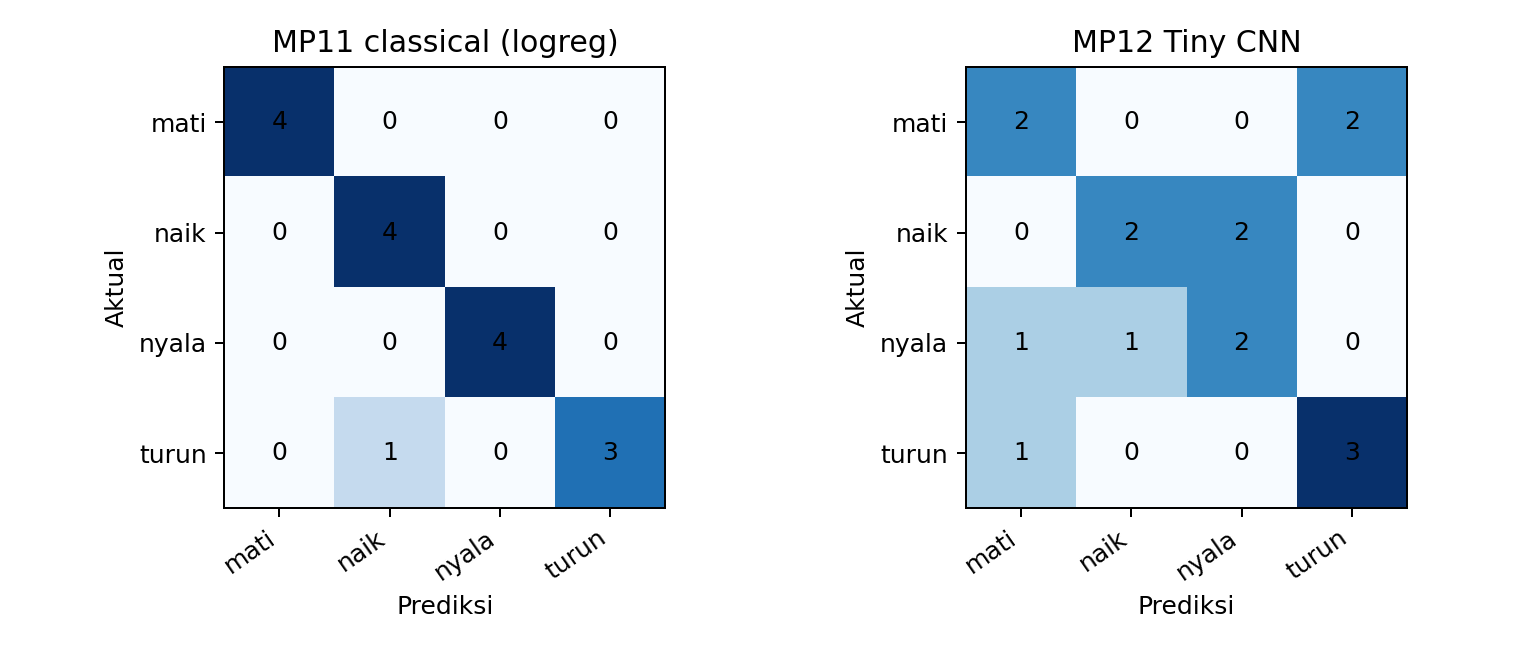

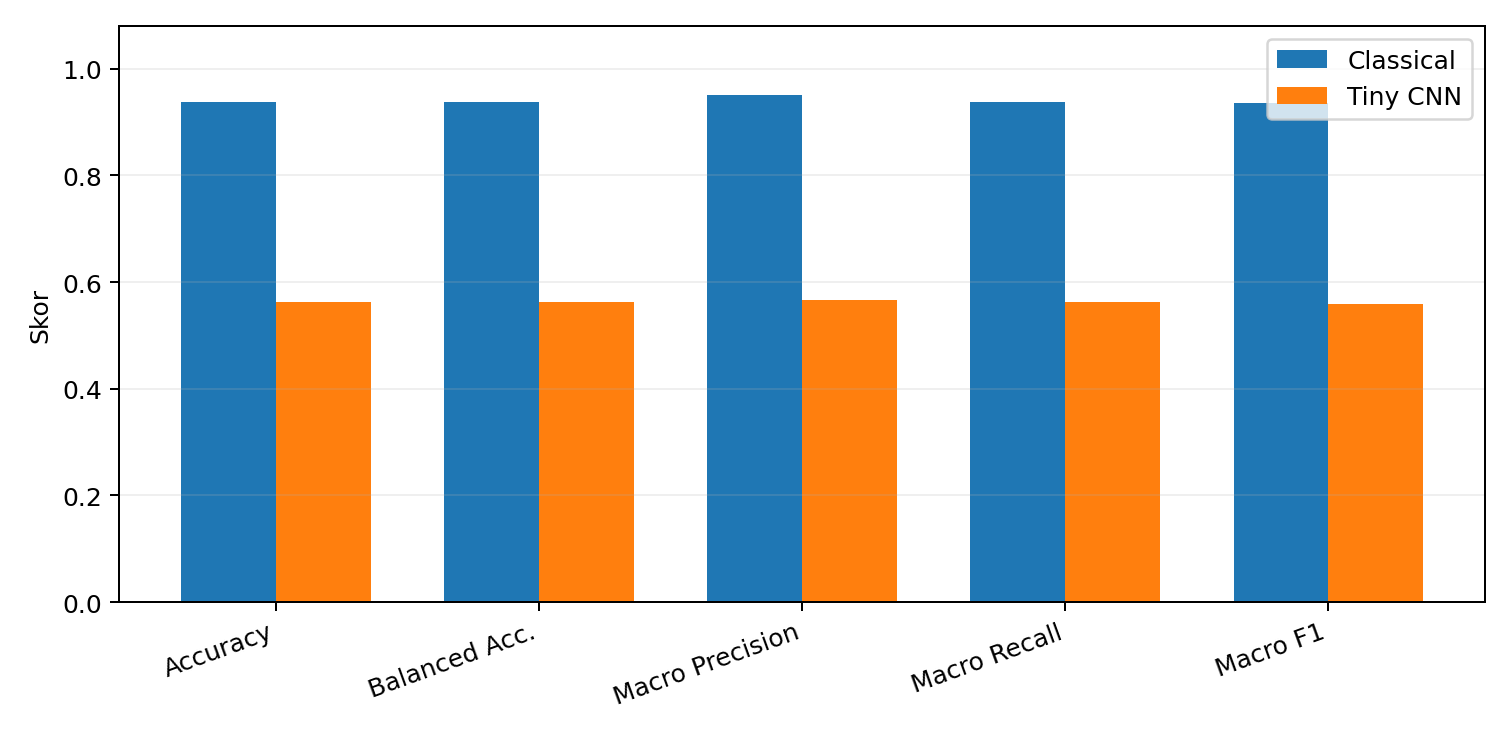

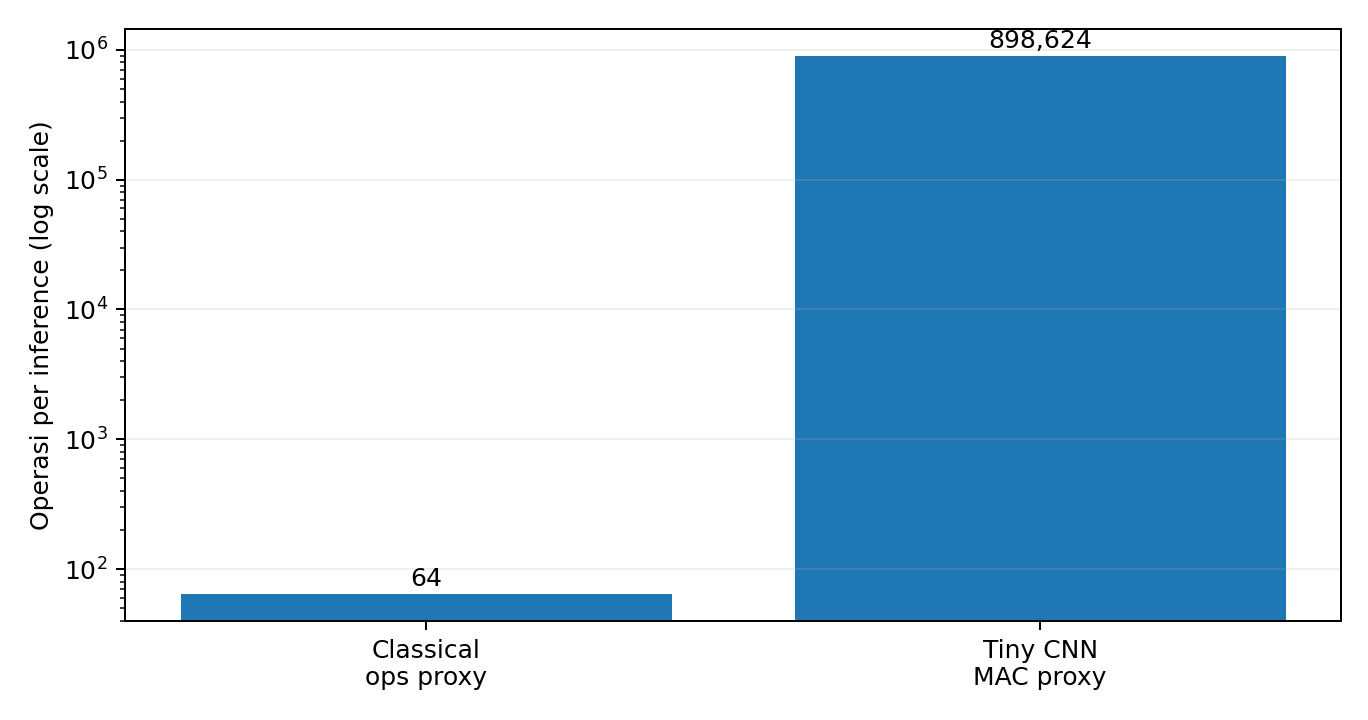

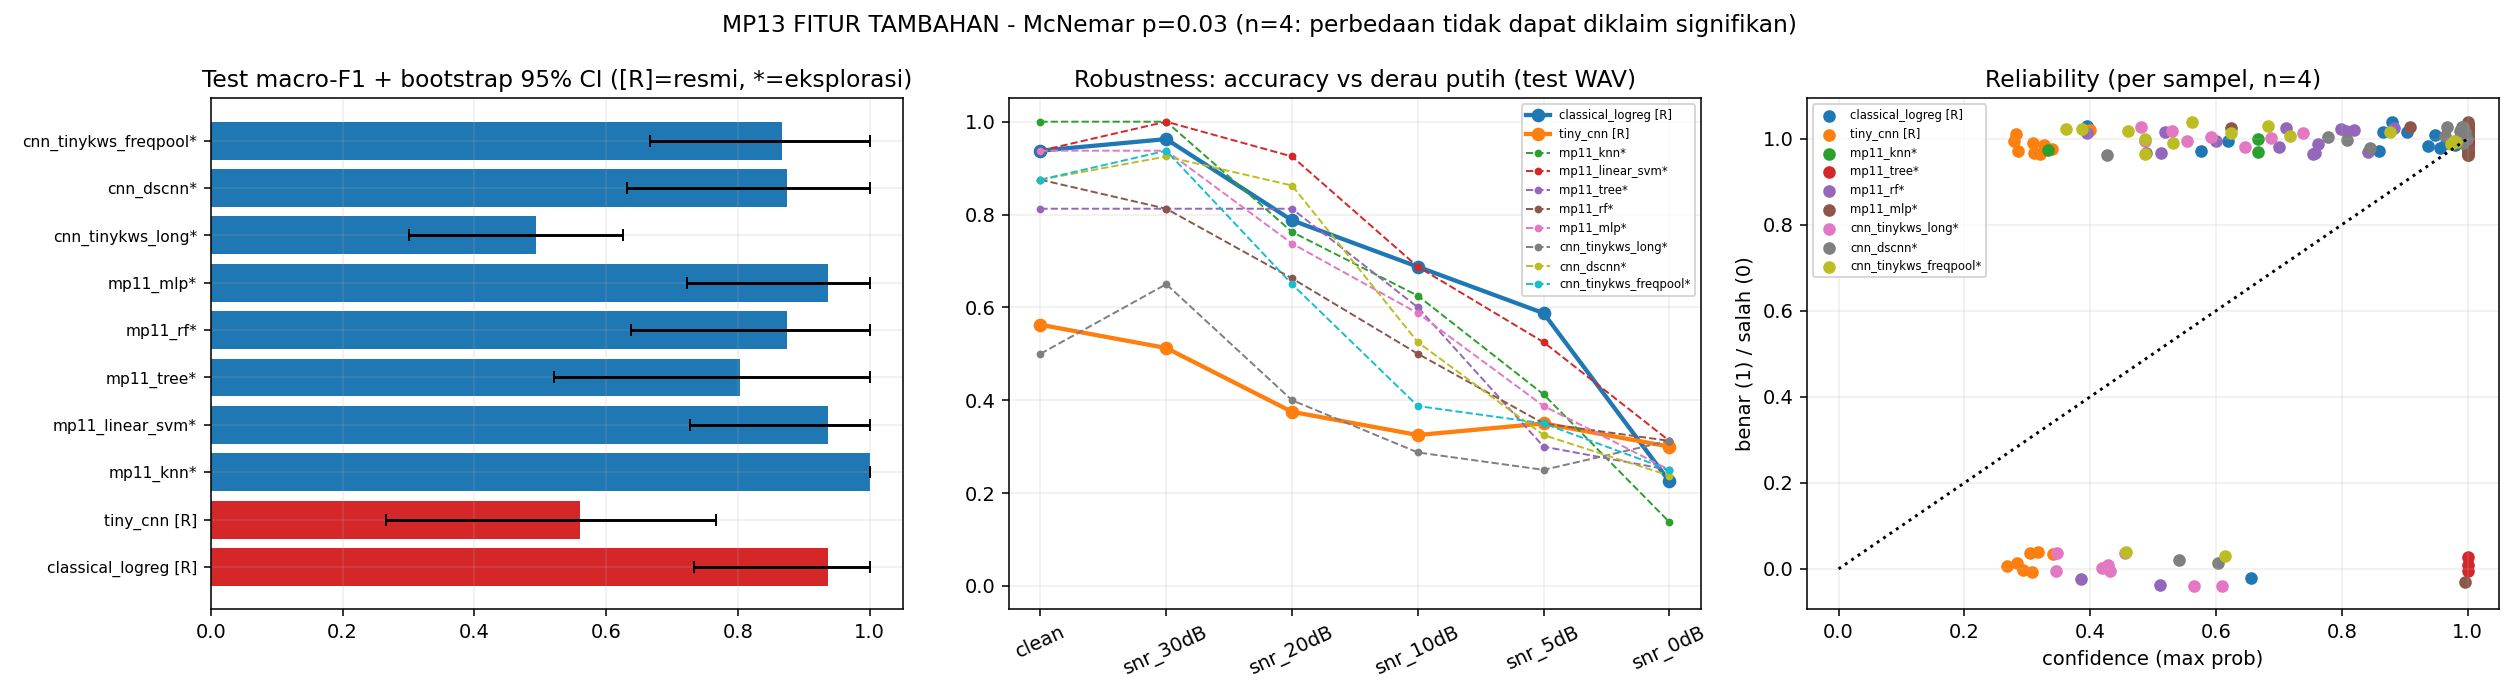

In [15]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp13_test_confusion_matrices.png', 'mp13_test_metric_comparison.png', 'mp13_resource_proxy.png', 'mp13_extension_evaluation_analysis.png']:
        display(Image(filename=str(OUT_FIG/p), width=820))